EDA-анализ

Карточка с Kaggle

Датасет - Toxic Russian Comments Dataset

Ссылка: https://www.kaggle.com/datasets/alexandersemiletov/toxic-russian-comments

This dataset contains labelled comments from the popular Russian social network ok.ru.
The data was used in a competition where participants had to automatically label each comment with at least one of the four predefined classes. The classes represent different levels of toxicity. The competition was held on the All Cups platform.
Each comment belongs to one of the following classes, with each label complying with the fastText formatting rules:

    __label__NORMAL - neutral user comments

    __label__INSULT - comments that humiliate a person

    __label__THREAT - comments with an explicit intent to harm another person

    __label__OBSCENITY - comments that contain a description or a threat of a sexual assault
Data overview:
count_of_elements: 248290
count_of_labels: 4
label_count:
 1. __label__NORMAL: 203685
 2. __label__INSULT: 28567
 3. __label__INSULT,__label__THREAT: 6317
 4. __label__THREAT: 5460
 5. __label__OBSCENITY: 2245
 6. __label__INSULT,__label__OBSCENITY: 1766
 7. __label__INSULT,__label__OBSCENITY,__label__THREAT: 176
 8. __label__OBSCENITY,__label__THREAT: 74

_______________________________________________
Шаг 1

Переведем весь датасет в пандас датафрейм для последующего удобства.
Импортируем все библиотеки для анализа в первом блоке. 

Датасет в пандас для последующего удобства
_______________________________________________

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import scipy.stats as stats
import nltk
from nltk.corpus import stopwords
from collections import Counter
nltk.download('stopwords') #Подгрузка стоп-слов
stop_ru = set(stopwords.words('russian')) #Стоп-слова на русском языке

data_list = []
dataset_filename = 'dataset.txt' #отдельно переменная с именем датасета
with open(dataset_filename,'r', encoding = 'utf-8') as file:
    for line in file:
        labels = line.split()[0]
        text = line[len(labels) + 1:].strip()
        labels = labels.split(",")
        mask = [1 if "__label__NORMAL" in labels else 0,
                1 if "__label__INSULT" in labels else 0,
                1 if "__label__THREAT" in labels else 0,
                1 if "__label__OBSCENITY" in labels else 0]
        data_list.append((text, *mask))
df = pd.DataFrame(data_list, columns=["text", "normal", "insult", "threat", "obscenity"])
labels = ['normal', 'insult', 'threat', 'obscenity'] #отдельно метки в списке для последующего использования

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/evgenya/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


_______________________________________________
Шаг 2.

Выведем основные статистические показатели для каждого признака в датасете.

Используем для этого функции: 
1. df.shape (Определим размеры датасета)
2. df.describe (Посмотрим статистику датасета),
3. df.info (Посмотрим сводную информацию о датасете)
_______________________________________________

In [2]:
"""
Здесь выводятся основные статистические показатели для каждого признака в датасете.
df.describe() создает быструю статистическую сводку по содержимому объекта
"""
print("="*50)
print("Размеры датасета")
num_rows, num_columns = df.shape
print(f"{num_rows=}")
print(f"{num_columns=}")
print("="*50)
print("Статистическая информация о датасете")
print(df.describe(include='all'))
print("="*50)
print("Сводная информация о датасете")
print(df.info())
print("="*50)
print("Дополнительно - на всякий случай, посмотрим, есть ли пропуски или нет")
print(df.isnull().sum()) # isnull() выдает массив из булловых значений, где пропуски обозначены как True, затем они суммируются
print("="*50)

Размеры датасета
num_rows=248290
num_columns=5
Статистическая информация о датасете
          text         normal         insult         threat      obscenity
count   248290  248290.000000  248290.000000  248290.000000  248290.000000
unique  248283            NaN            NaN            NaN            NaN
top      сжечь            NaN            NaN            NaN            NaN
freq         2            NaN            NaN            NaN            NaN
mean       NaN       0.820351       0.148318       0.048439       0.017161
std        NaN       0.383895       0.355416       0.214693       0.129873
min        NaN       0.000000       0.000000       0.000000       0.000000
25%        NaN       1.000000       0.000000       0.000000       0.000000
50%        NaN       1.000000       0.000000       0.000000       0.000000
75%        NaN       1.000000       0.000000       0.000000       0.000000
max        NaN       1.000000       1.000000       1.000000       1.000000
Сводная информац

_______________________________________________
Выводы по первичному анализу датасета
1. Всего в датасете 248290 объекта и 5 признаков
2. В датасете присутствует 7 дубликатов, в последующем их нужно проанализировать, выбрать и данную ситуацию разрешить;
3. Статистика здесь показывается для количественных признаков - для текстовой информации этих данных нет, что нормально;
4. В датасете нет пропусков, что значительно упрощает работу с данными в будущем;
5. Выводы по количественным значениям: наблюдается смещение данных в сторону normal, что говорит о том, что подавляющее большинство сообщений в датасете относятся к этой категории, однако это предстоит еще дополнительно оценить.
_______________________________________________

_______________________________________________
Шаг 3

Найдем все дубликаты, удалим их, проанализируем на наличие аномалий
_______________________________________________

In [3]:
"""
В данном блоке представлены различные, дополнительные проверки датасета
"""
#1 Проверка на наличие дубликатов в текстовых данных
print("#2 Проверка на наличие дубликатов в текстовых сообщениях")
dublicated_text = df['text'].duplicated() #Строки с дублированным содержанием в text
dubplicated_nums = dublicated_text.sum() #количество строк с дублированным содержанием в text
duplicated_text_explicit = df[df['text'].duplicated(keep=False)] #Строки с дублированным содержанием в text в явном виде
duplicated_text_explicit = duplicated_text_explicit.sort_values(by='text') #Строки с дублированным содержанием в text после сортировки для удобства восприятия
print(f'Число дубликатов в текстовых данных = {dubplicated_nums}')
print("Ниже будут представлены дубликаты:")
print(duplicated_text_explicit)
print("Поиск дубликатов нашел следующие результаты.\nЕсть повторяющиеся строки.")
print("Решение по поводу дубликатов: удалить объекты-.")
print("Есть одна небольшая аномалия - сообщение со слов 'сжечь' повторяется в двух категориях - normal и threat")
print("Решение по поводу слова 'сжечь': оставить только в категории threat.")

#2 Проверка на наличие дубликатов в текстовых сообщениях
Число дубликатов в текстовых данных = 7
Ниже будут представлены дубликаты:
                     text  normal  insult  threat  obscenity
9006                а это       1       0       0          0
82917               а это       1       0       0          0
55549         каждый день       1       0       0          0
107132        каждый день       1       0       0          0
45202            красивая       1       0       0          0
143372           красивая       1       0       0          0
8909          расстрелять       0       0       1          0
81190         расстрелять       0       0       1          0
188008  расстрелять нахуй       0       0       1          0
201004  расстрелять нахуй       0       0       1          0
76764     с днем рождения       1       0       0          0
146488    с днем рождения       1       0       0          0
218287              сжечь       1       0       0          0
230339        

_______________________________________________
Выводы по дополнительным проверкам
1. Дубликаты найдены, отсортированы и выведены. Дублирующие сообщения удалены из датасета;
2. Текст "сжечь" предлагается оставить только в категории threat, так как без контекста это слово не воспринимается как normal, а по своему семантическому значению ближе именно к угрозе.
_______________________________________________

In [4]:
#Обновление датасета после шага 1
print("="*50)
print("#3 Обновил датасет после удаления дублирующих строк и удаления строки 'сжечь' из датасета с тональностью 'нормально', оставил только с тональностью 'угроза'")
duplicated_text_indices = [9006, 55549, 45202, 8909, 188008, 76764, 218287] #Строки с дублированным содержанием в text, индексы, я их выбрал вручную
df_updated = df.drop(duplicated_text_indices).reset_index(drop=True) #обновленный датасет после того, как убраны объекты дубликаты
print("Дополнительная проверка - проверяем, что больше нет повторений")
dublicated_text = df_updated['text'].duplicated() #Строки с дублированным содержанием в text
dubplicated_nums = dublicated_text.sum() #количество строк с дублированным содержанием в text
print(f'Число дубликатов в текстовых данных = {dubplicated_nums}')
print("="*50)

#3 Обновил датасет после удаления дублирующих строк и удаления строки 'сжечь' из датасета с тональностью 'нормально', оставил только с тональностью 'угроза'
Дополнительная проверка - проверяем, что больше нет повторений
Число дубликатов в текстовых данных = 0


_______________________________________________
Выводы:
1. Изначальный датасет обновлен, сохранен в новую переменную - df_updated. 
2. Обновленный датасет не содержит дублирующих объектов, аномалий и пропусков.
_______________________________________________

_______________________________________________
Шаг 4

Анализ обновленного датасета df_updated на дисбаланс классов
_______________________________________________

Количество сообщений каждой из категорий
normal       203680
insult        36826
threat        12025
obscenity      4261
dtype: int64
Процентное соотношение сообщений каждой из категорий относительно всего корпуса
normal       82.03 %
insult       14.83 %
threat        4.84 %
obscenity     1.72 %
dtype: object


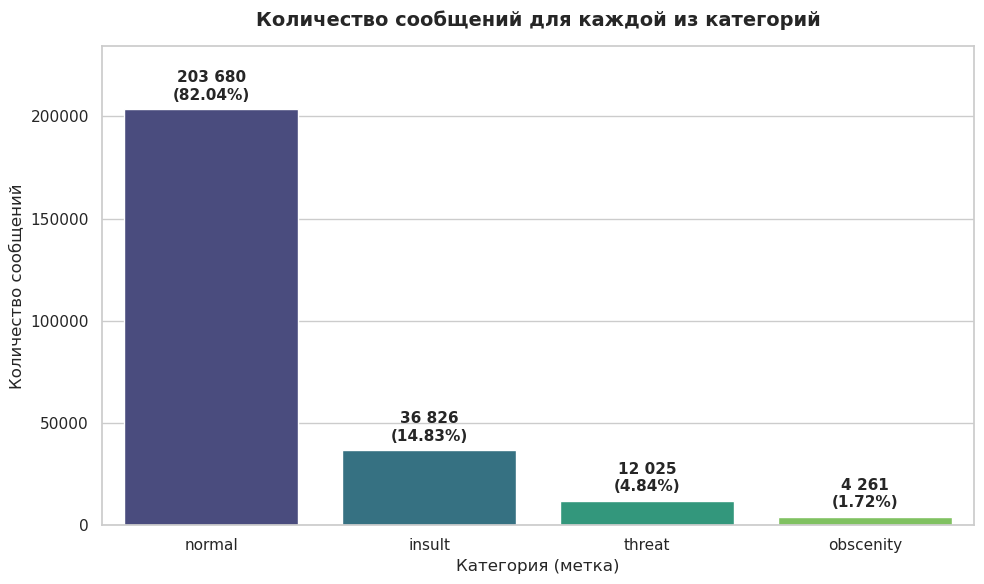

In [5]:
print("="*50)
print("Количество сообщений каждой из категорий")
freq = df_updated[labels].sum().sort_values(ascending=False)
print(freq)
print("="*50)
print("Процентное соотношение сообщений каждой из категорий относительно всего корпуса")
print((freq / len(df) * 100).round(2).astype(str) + ' %')
print("="*50)

# Визуализация
labels = ['normal', 'insult', 'threat', 'obscenity']

# Частоты и проценты от обновленного датасета
freq = df_updated[labels].sum().sort_values(ascending=False)
pct = (freq / len(df_updated) * 100).round(2)

# Настройка размеров
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Столбчатая диаграмма
ax = sns.barplot(
    x=freq.index, 
    y=freq.values, 
    palette='viridis', 
    hue=freq.index, 
    legend=False
)

# Подписи над каждым столбцом: "Количество (Процент%)"
for i, (count, percent) in enumerate(zip(freq.values, pct.values)):
    ax.text(
        i, 
        count + (freq.max() * 0.015),  # небольшой отступ сверху от столбца
        f"{count:,}\n({percent}%)".replace(',', ' '), 
        ha='center', 
        va='bottom', 
        fontsize=11, 
        fontweight='bold'
    )

plt.title('Количество сообщений для каждой из категорий', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Категория (метка)', fontsize=12)
plt.ylabel('Количество сообщений', fontsize=12)
plt.ylim(0, freq.max() * 1.15)

plt.tight_layout()
plt.show()  

_______________________________________________
Выводы: 
1. Можно отметить достаточно сильный дисбаланс классов в сторону normal.
Потенциально это говорит о том, что в будущем нужно аккуратно выбирать метрики под модели - стандартные метрики вроде Accuracy тут работать не будут
_______________________________________________

_______________________________________________
Шаг 5

Можно рассмотреть и визуализировать дополнительные признаки к текстовым сообщениям:
 1. Количество символов в каждом сообщении (len_chars);
 2. Длина каждого сообщения (len_words).
 3. Наличие шума в данных.
_______________________________________________


                                                text  normal  insult  threat  \
0                               скотина! что сказать       0       1       0   
1  я сегодня проезжала по рабочей и между домами ...       1       0       0   
2  очередной лохотрон. зачем придумывать очередно...       1       0       0   
3  ретро дежавю ... сложно понять чужое сердце , ...       1       0       0   
4            а когда мы статус агрогородка получили?       1       0       0   

   obscenity  len_chars  len_words  
0          0         20          3  
1          0        180         29  
2          0        379         54  
3          0         72         12  
4          0         39          6  
Минимальное количество слов в сообщении 1
Максимальное количество слов в сообщении 267
Среднее значение количества слов в сообщении 12.50
Медианное значение количества слов в сообщении 8.00
Минимальное количество символов в сообщении 2
Максимальное количество символов в сообщении 998
Среднее знач

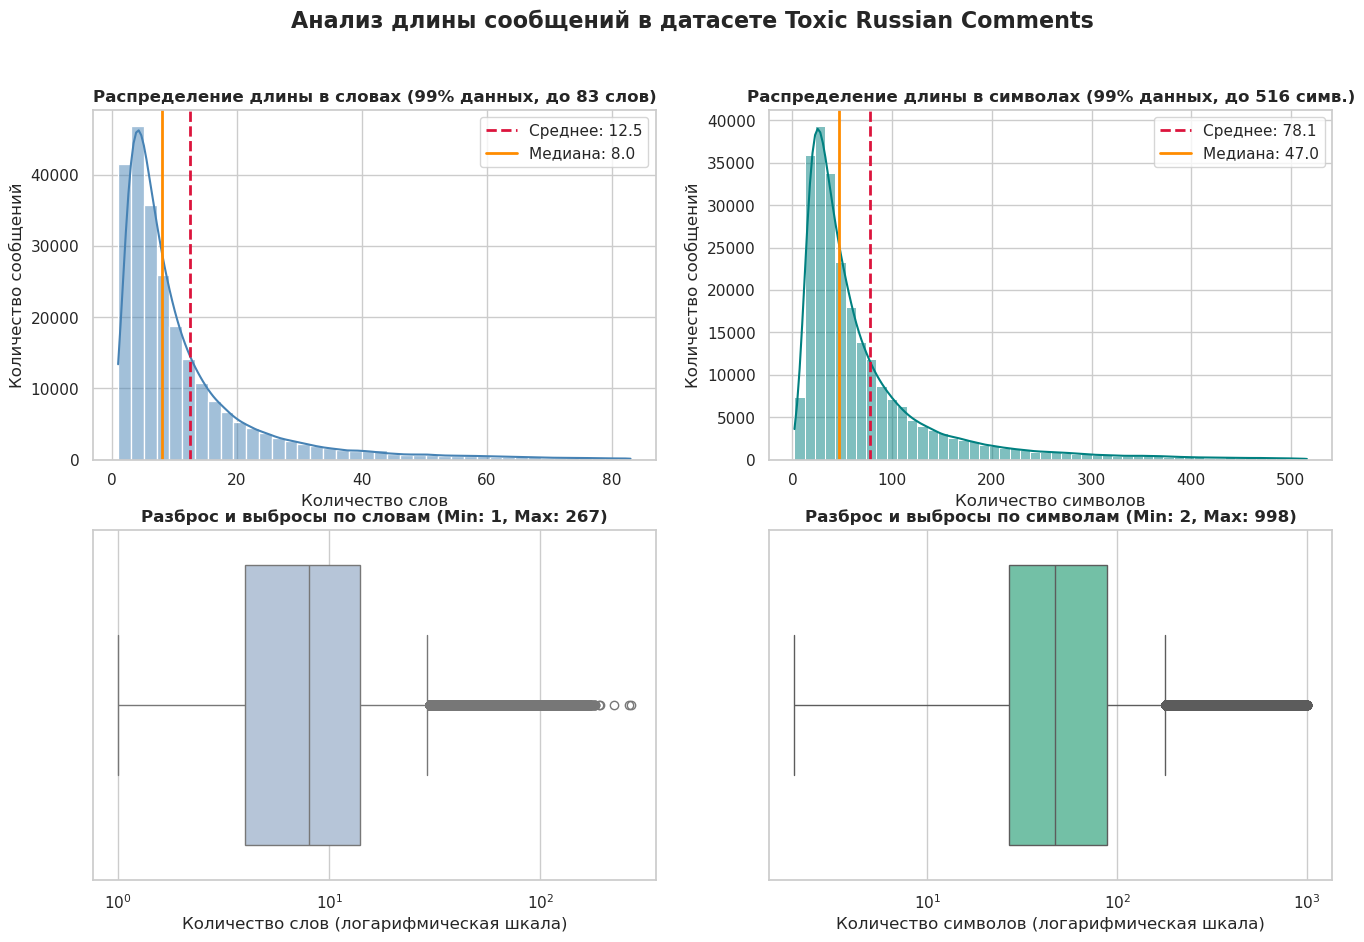

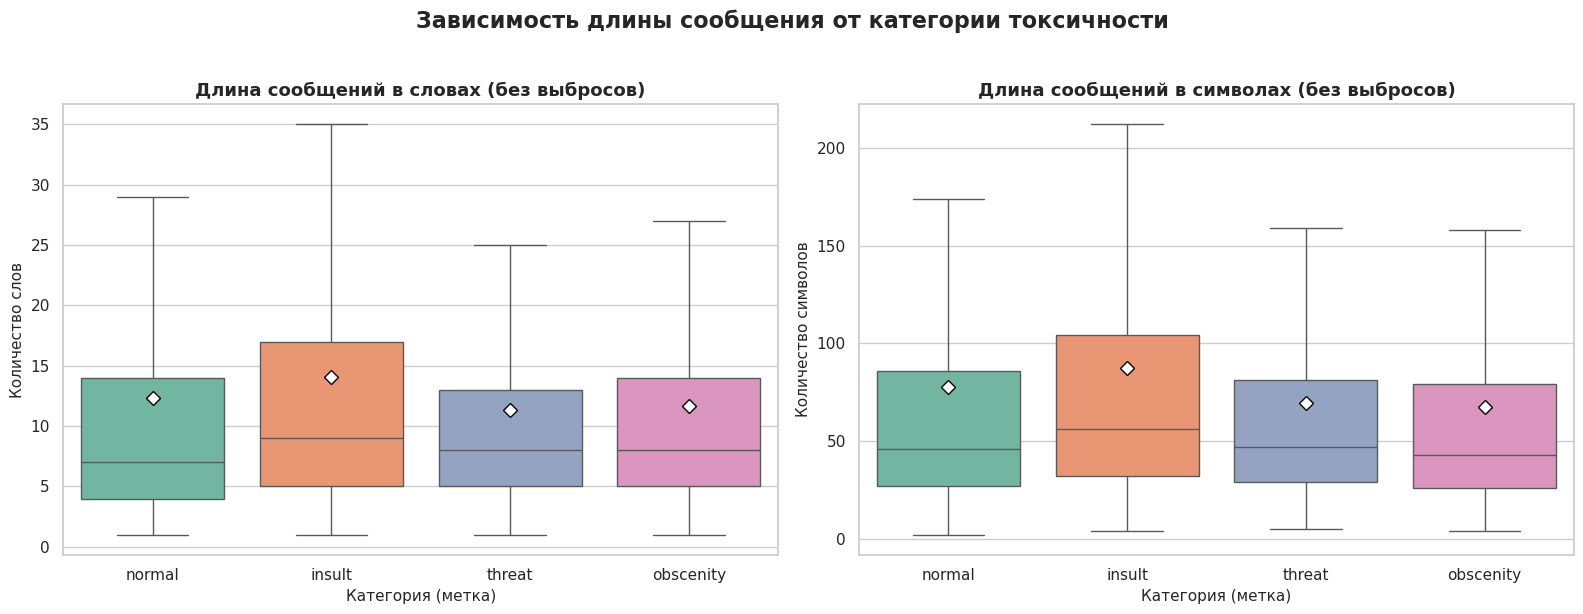

In [6]:
df_updated['len_chars'] = df_updated['text'].str.len() #количество символов в сообщении (включая пробелы и пунктуацию)
df_updated['len_words'] = df_updated['text'].str.split().str.len() #количество слов в сообщении
print(df_updated.head(5))
print("="*50)
min_len_words = df_updated['len_words'].min()
max_len_words = df_updated['len_words'].max()
mean_len_words = df_updated['len_words'].mean()
median_len_words = df_updated['len_words'].median()

min_len_chars = df_updated['len_chars'].min()
max_len_chars = df_updated['len_chars'].max()
mean_len_chars = df_updated['len_chars'].mean()
median_len_chars = df_updated['len_chars'].median()
print("="*50)
print(f"Минимальное количество слов в сообщении {min_len_words}\nМаксимальное количество слов в сообщении {max_len_words}\nСреднее значение количества слов в сообщении {mean_len_words:.2f}\nМедианное значение количества слов в сообщении {median_len_words:.2f}")
print("="*50)
print(f"Минимальное количество символов в сообщении {min_len_chars}\nМаксимальное количество символов в сообщении {max_len_chars}\nСреднее значение количества символов в сообщении {mean_len_chars:.2f}\nМедианное значение количества символов в сообщении {median_len_chars:.2f}")

# Визуализация
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Анализ длины сообщений в датасете Toxic Russian Comments', fontsize=16, fontweight='bold')

# --- 1. Гистограмма: количество слов (до 99-го перцентиля) ---
p99_words = df_updated['len_words'].quantile(0.99)
sns.histplot(
    df_updated[df_updated['len_words'] <= p99_words]['len_words'], 
    bins=40, kde=True, ax=axes[0, 0], color='steelblue'
)
axes[0, 0].axvline(mean_len_words, color='crimson', linestyle='--', linewidth=2, label=f'Среднее: {mean_len_words:.1f}')
axes[0, 0].axvline(median_len_words, color='darkorange', linestyle='-', linewidth=2, label=f'Медиана: {median_len_words:.1f}')
axes[0, 0].set_title(f'Распределение длины в словах (99% данных, до {int(p99_words)} слов)', fontweight='bold')
axes[0, 0].set_xlabel('Количество слов')
axes[0, 0].set_ylabel('Количество сообщений')
axes[0, 0].legend()

# --- 2. Гистограмма: количество символов (до 99-го перцентиля) ---
p99_chars = df_updated['len_chars'].quantile(0.99)
sns.histplot(
    df_updated[df_updated['len_chars'] <= p99_chars]['len_chars'], 
    bins=50, kde=True, ax=axes[0, 1], color='teal'
)
axes[0, 1].axvline(mean_len_chars, color='crimson', linestyle='--', linewidth=2, label=f'Среднее: {mean_len_chars:.1f}')
axes[0, 1].axvline(median_len_chars, color='darkorange', linestyle='-', linewidth=2, label=f'Медиана: {median_len_chars:.1f}')
axes[0, 1].set_title(f'Распределение длины в символах (99% данных, до {int(p99_chars)} симв.)', fontweight='bold')
axes[0, 1].set_xlabel('Количество символов')
axes[0, 1].set_ylabel('Количество сообщений')
axes[0, 1].legend()

# --- 3. Boxplot (Ящик с усами): слова (весь диапазон с min и max) ---
sns.boxplot(x=df_updated['len_words'], ax=axes[1, 0], color='lightsteelblue')
axes[1, 0].set_title(f'Разброс и выбросы по словам (Min: {min_len_words}, Max: {max_len_words})', fontweight='bold')
axes[1, 0].set_xlabel('Количество слов (логарифмическая шкала)')
axes[1, 0].set_xscale('log')  # Логарифмическая шкала, чтобы были видны и min, и max

# --- 4. Boxplot (Ящик с усами): символы (весь диапазон с min и max) ---
sns.boxplot(x=df_updated['len_chars'], ax=axes[1, 1], color='mediumaquamarine')
axes[1, 1].set_title(f'Разброс и выбросы по символам (Min: {min_len_chars}, Max: {max_len_chars})', fontweight='bold')
axes[1, 1].set_xlabel('Количество символов (логарифмическая шкала)')
axes[1, 1].set_xscale('log')

# ---5. Количество слов по меткам
labels = ['normal', 'insult', 'threat', 'obscenity']
df_melted = df_updated.melt(
    id_vars=['len_words', 'len_chars'],
    value_vars=labels,
    var_name='label',
    value_name='is_present',
)
df_melted = df_melted[df_melted['is_present'] == 1]

# Сетка 1x2 и распаковка осей в отдельные переменные
sns.set_theme(style='whitegrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    'Зависимость длины сообщения от категории токсичности',
    fontsize=16,
    fontweight='bold',
    y=1.02,
)

# Настройки маркера для отображения среднего значения
mean_props = {
    'marker': 'D',
    'markerfacecolor': 'white',
    'markeredgecolor': 'black',
    'markersize': 7,
}

# --- График 1: Длина в словах по меткам ---
sns.boxplot(
    data=df_melted,
    x='label',
    y='len_words',
    ax=ax1,
    palette='Set2',
    hue='label',
    legend=False,
    showfliers=False,  # скрываем экстремальные выбросы для читаемости
    showmeans=True,  # показываем среднее значение белым ромбом
    meanprops=mean_props,
)
ax1.set_title(
    'Длина сообщений в словах (без выбросов)', fontsize=13, fontweight='bold'
)
ax1.set_xlabel('Категория (метка)', fontsize=11)
ax1.set_ylabel('Количество слов', fontsize=11)

# --- График 2: Длина в символах по меткам ---
sns.boxplot(
    data=df_melted,
    x='label',
    y='len_chars',
    ax=ax2,
    palette='Set2',
    hue='label',
    legend=False,
    showfliers=False,
    showmeans=True,
    meanprops=mean_props,
)
ax2.set_title(
    'Длина сообщений в символах (без выбросов)', fontsize=13, fontweight='bold'
)
ax2.set_xlabel('Категория (метка)', fontsize=11)
ax2.set_ylabel('Количество символов', fontsize=11)


def max_without_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    # Реальное максимальное значение, не превышающее границу выбросов
    return series[series <= upper_bound].max()

max_no_outliers = (
    df_melted.groupby('label')[['len_words', 'len_chars']]
    .agg(max_without_outliers)
    .loc[labels]
)
max_no_outliers.columns = ['Макс. слов (без выбросов)', 'Макс. символов (без выбросов)']

print('=' * 60)
print('Максимальная длина сообщений по категориям (без выбросов):')
print(max_no_outliers)
print('=' * 60)

plt.tight_layout()
plt.show()  


=== ШУМ В ДАННЫХ ===
Ссылки (URL): 1578 (0.64%)
HTML-теги: 0 (0.00%)
Упоминания (@user): 0 (0.00%)
Латиница: 11668 (4.70%)
Цифры: 28651 (11.54%)
Эмодзи / спецсимволы: 29934 (12.06%)


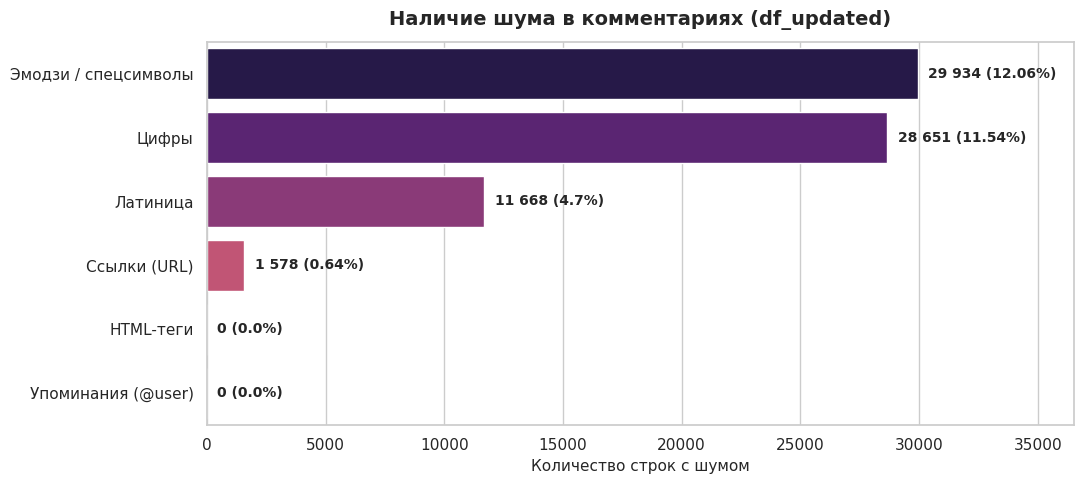

In [7]:
# Шум в данных

print("\n=== ШУМ В ДАННЫХ ===")
text_col = df_updated['text'].fillna('').astype(str)
total_rows = len(df_updated)

noise_stats = {
    'Ссылки (URL)': text_col.str.contains(r'http\S+|www\.\S+', regex=True).sum(),
    'HTML-теги': text_col.str.contains(r'<[^>]+>', regex=True).sum(),
    'Упоминания (@user)': text_col.str.contains(r'@\w+', regex=True).sum(),
    'Латиница': text_col.str.contains(r'[a-zA-Z]', regex=True).sum(),
    'Цифры': text_col.str.contains(r'\d', regex=True).sum(),
    'Эмодзи / спецсимволы': text_col.str.contains(r'[^\w\s.,!?;:\-—()"\'«»]', regex=True).sum()
}

for name, count in noise_stats.items():
    pct = (count / len(df)) * 100
    print(f"{name}: {count} ({pct:.2f}%)")

sorted_items = sorted(noise_stats.items(), key=lambda x: x[1], reverse=True)
noise_names, noise_counts = zip(*sorted_items)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(
    x=list(noise_counts),
    y=list(noise_names),
    ax=ax,
    palette='magma',
    hue=list(noise_names),
    legend=False
)

max_val = max(noise_counts)
for i, count in enumerate(noise_counts):
    pct = round((count / total_rows) * 100, 2)
    ax.text(
        count + max_val * 0.015,
        i,
        f"{count:,} ({pct}%)".replace(',', ' '),
        va='center',
        fontsize=10,
        fontweight='bold'
    )

ax.set_title('Наличие шума в комментариях (df_updated)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Количество строк с шумом', fontsize=11)
ax.set_ylabel('')
ax.set_xlim(0, max_val * 1.22)

plt.tight_layout()
plt.show()


_______________________________________________
Выводы: 
1. В сообщениях присутствуют фрагменты длиной от 1 до 267 слов, при этом максимальное число символов составляет 998 штук
2. Основная масса комментариев (95–99%) укладывается примерно в 60–80 слов (около 400–550 символов), хотя единичные выбросы могут быть до 998 символов. Знаичит, можно не брать слишком большой запас длины сообщения при обучении модели. 
3. По ящикам с усами видно, что длина сообщения не является чётким разделяющим признаком для меток, поэтому нет смысла добавлять длину в признаки меток.
4. Шум в данных:
* В данных отсутствуют никнеймы(@user) и html-теги, доля ссылок миимальна и их можно удалить, так как они нерелевантны для разденеия сообщений на метки. 
* Эмодзи и спецсимволы являются важной частью сообщений и могут быть признаком для разделения по меткам, поэтому нужно их учитывать. 
* Латиница может использоваться в сообщениях для записи русских слов латинскими буквами или же для обхода блокировок за мат(замена русских букв похожими латинскими). Такие данные нужны для разметки, и их надо учитывать.
* Цифры, вероятно, не несут особого смысла для разметки, но и не мешают обрабатывать данные. Можно оставить как есть. 

_______________________________________________
Шаг 6

На данном шаге анализируется количество наиболее часто встречаемых слов в датасете:
1. Стоп-слова;
2. Наиболее часто встречаемые слова в датасете в целом;
3. Наиболее часто встречаемые слова в датасете по маркерам.


Примечания:
1. Все слова включаются нормализированными - приводятся к нижнему регистру, убирается пунктуация (за исключением стоп-слов);
2. Проходят фильтр по длине - len(word) > 3, чтобы избавиться от мусорных слов и знаков препинания(за исключением стоп-слов);
3. Проходят фильтр по стоп-словам (для пунктов 2 и 3)./
_______________________________________________

Наиболее часто встречающиеся стоп-слова в датасете
и               101264
не              78144
в               74161
на              44031
а               40918
с               32571
что             30053
я               22227
как             21302
у               20963
Наиболее часто встречающиеся слова в датасете
очень           8381
просто          5669
тебе            4172
сколько         3796
спасибо         3715
всем            3673
пусть           3472
таких           3302
такие           3124
люди            3111


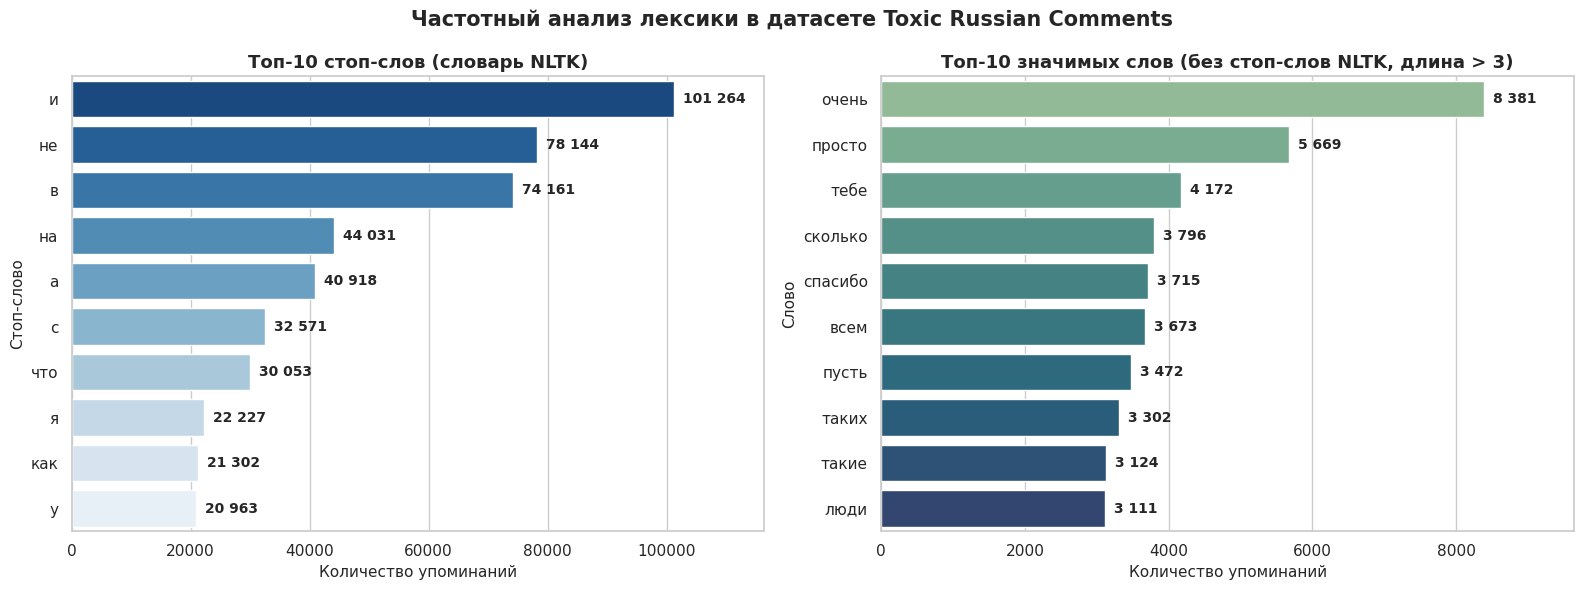

In [8]:
"""
Пункт 1.
Анализ наиболее часто встречающихся стоп-слов
"""
words = [w.lower() for text in df_updated['text'] for w in text.split()]
counter = Counter(words)
stop_stats = [(w, c) for w, c in counter.most_common() if w in stop_ru][:10]
print("="*50)
print("Наиболее часто встречающиеся стоп-слова в датасете")
for w, c in stop_stats:
    print(f"{w:15s} {c}")
print("="*50)
"""
Пункт 2.
Анализ наиболее часто встречающихся слов в датасете в целом
"""
print("Наиболее часто встречающиеся слова в датасете")
words_stats = [(w, c) for w, c in counter.most_common() if w not in stop_ru and len(w) > 3][:10]
for w, c in words_stats:
    print(f"{w:15s} {c}")

# Визуализация
from collections import Counter
import nltk
from nltk.corpus import stopwords

# 1. Загрузка и инициализация русских стоп-слов из NLTK
nltk.download('stopwords', quiet=True)
stop_ru = set(stopwords.words('russian'))

# 2. Подсчёт частоты слов
words = [w.lower() for text in df_updated['text'] for w in str(text).split()]
counter = Counter(words)

stop_stats = [(w, c) for w, c in counter.most_common() if w in stop_ru][:10]
words_stats = [
    (w, c) for w, c in counter.most_common() if w not in stop_ru and len(w) > 3
][:10]

# 3. Визуализация результатов
stop_words, stop_counts = zip(*stop_stats)
top_words, top_counts = zip(*words_stats)

sns.set_theme(style='whitegrid')
# Распаковка осей в переменные ax1 и ax2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    'Частотный анализ лексики в датасете Toxic Russian Comments',
    fontsize=15,
    fontweight='bold',
)

# График 1: Топ-10 стоп-слов (на ax1)
sns.barplot(
    x=list(stop_counts),
    y=list(stop_words),
    ax=ax1,
    palette='Blues_r',
    hue=list(stop_words),
    legend=False,
)
ax1.set_title(
    'Топ-10 стоп-слов (словарь NLTK)', fontsize=13, fontweight='bold'
)
ax1.set_xlabel('Количество упоминаний', fontsize=11)
ax1.set_ylabel('Стоп-слово', fontsize=11)
ax1.set_xlim(0, max(stop_counts) * 1.15)

for i, count in enumerate(stop_counts):
  ax1.text(
      count + max(stop_counts) * 0.015,
      i,
      f'{count:,}'.replace(',', ' '),
      va='center',
      fontsize=10,
      fontweight='bold',
  )

# График 2: Топ-10 значимых слов (на ax2)
sns.barplot(
    x=list(top_counts),
    y=list(top_words),
    ax=ax2,
    palette='crest',
    hue=list(top_words),
    legend=False,
)
ax2.set_title(
    'Топ-10 значимых слов (без стоп-слов NLTK, длина > 3)',
    fontsize=13,
    fontweight='bold',
)
ax2.set_xlabel('Количество упоминаний', fontsize=11)
ax2.set_ylabel('Слово', fontsize=11)
ax2.set_xlim(0, max(top_counts) * 1.15)

for i, count in enumerate(top_counts):
  ax2.text(
      count + max(top_counts) * 0.015,
      i,
      f'{count:,}'.replace(',', ' '),
      va='center',
      fontsize=10,
      fontweight='bold',
  )

plt.tight_layout()
plt.show()


In [9]:
"""
Пункт 3.
Анализ наиболее часто встречающихся слов в датасете по меткам

"""
def count_words(df, label, stop, n, n_gap = 3):
    """
    В данной функции реализован расчет количества наиболее часто встречаемых слов в датасете
    Входные параметры:
        - Датасет df
        - Интересующая метка label
        - Список стоп-слов stop,
        - Количество слов n, которые мы хотим вывести,
        - n_gap - ограничение по длине выдаваемых слов.
    Выходные параметры:
        - список из кортежей (<слово>,<количество появлений>) первых n наиболее часто встречающихся слов в датасете df с выбранной меткой label
    """
    counter = Counter()
    mask = (df[label] == 1)
    for text in df.loc[mask,'text']:
        for word in text.split():
            w = word.lower().strip('.,!?;:()[]"\'')
            if len(w) < n_gap:
                continue
            if not w.isalpha():
                continue
            if w in stop:
                continue
            counter[w] += 1
    return counter.most_common(n)



n_words = 20 #число выдаваемых слов
n_gap = 3 # ограничение по длине выдаваемых слов
for lab in labels:
    print(f'Наиболее часто встречаемые слова для метки {lab}')
    top_words_list = count_words(df_updated, lab, stop_ru,n_words, n_gap)
    for word, cnt in top_words_list:
        print(f"{word:20s} {cnt}")
    print("="*50)
    

Наиболее часто встречаемые слова для метки normal
это                  22997
очень                8358
спасибо              5128
просто               4879
ещё                  4585
всё                  4343
здоровья             3846
всем                 3717
лет                  3551
сколько              3516
люди                 3366
тебе                 3033
нужно                2991
день                 2945
время                2854
пусть                2794
здравствуйте         2656
такие                2563
почему               2352
нам                  2327
Наиболее часто встречаемые слова для метки insult
это                  4411
сука                 1436
тебе                 1400
тварь                1332
таких                1303
хуй                  1190
мразь                1076
пидор                1043
ещё                  1034
этих                 1033
просто               951
твари                861
всё                  816
народ                688
такие              

Опционально: добавим дополнительные стоп-слова, которые попали в список наиболее часто встречаемых слов в сообщениях, в изначальный список стоп-слов.
Возможно, это поможет лучше конкретизировать лексику по каждой метке.
_______________________________________________

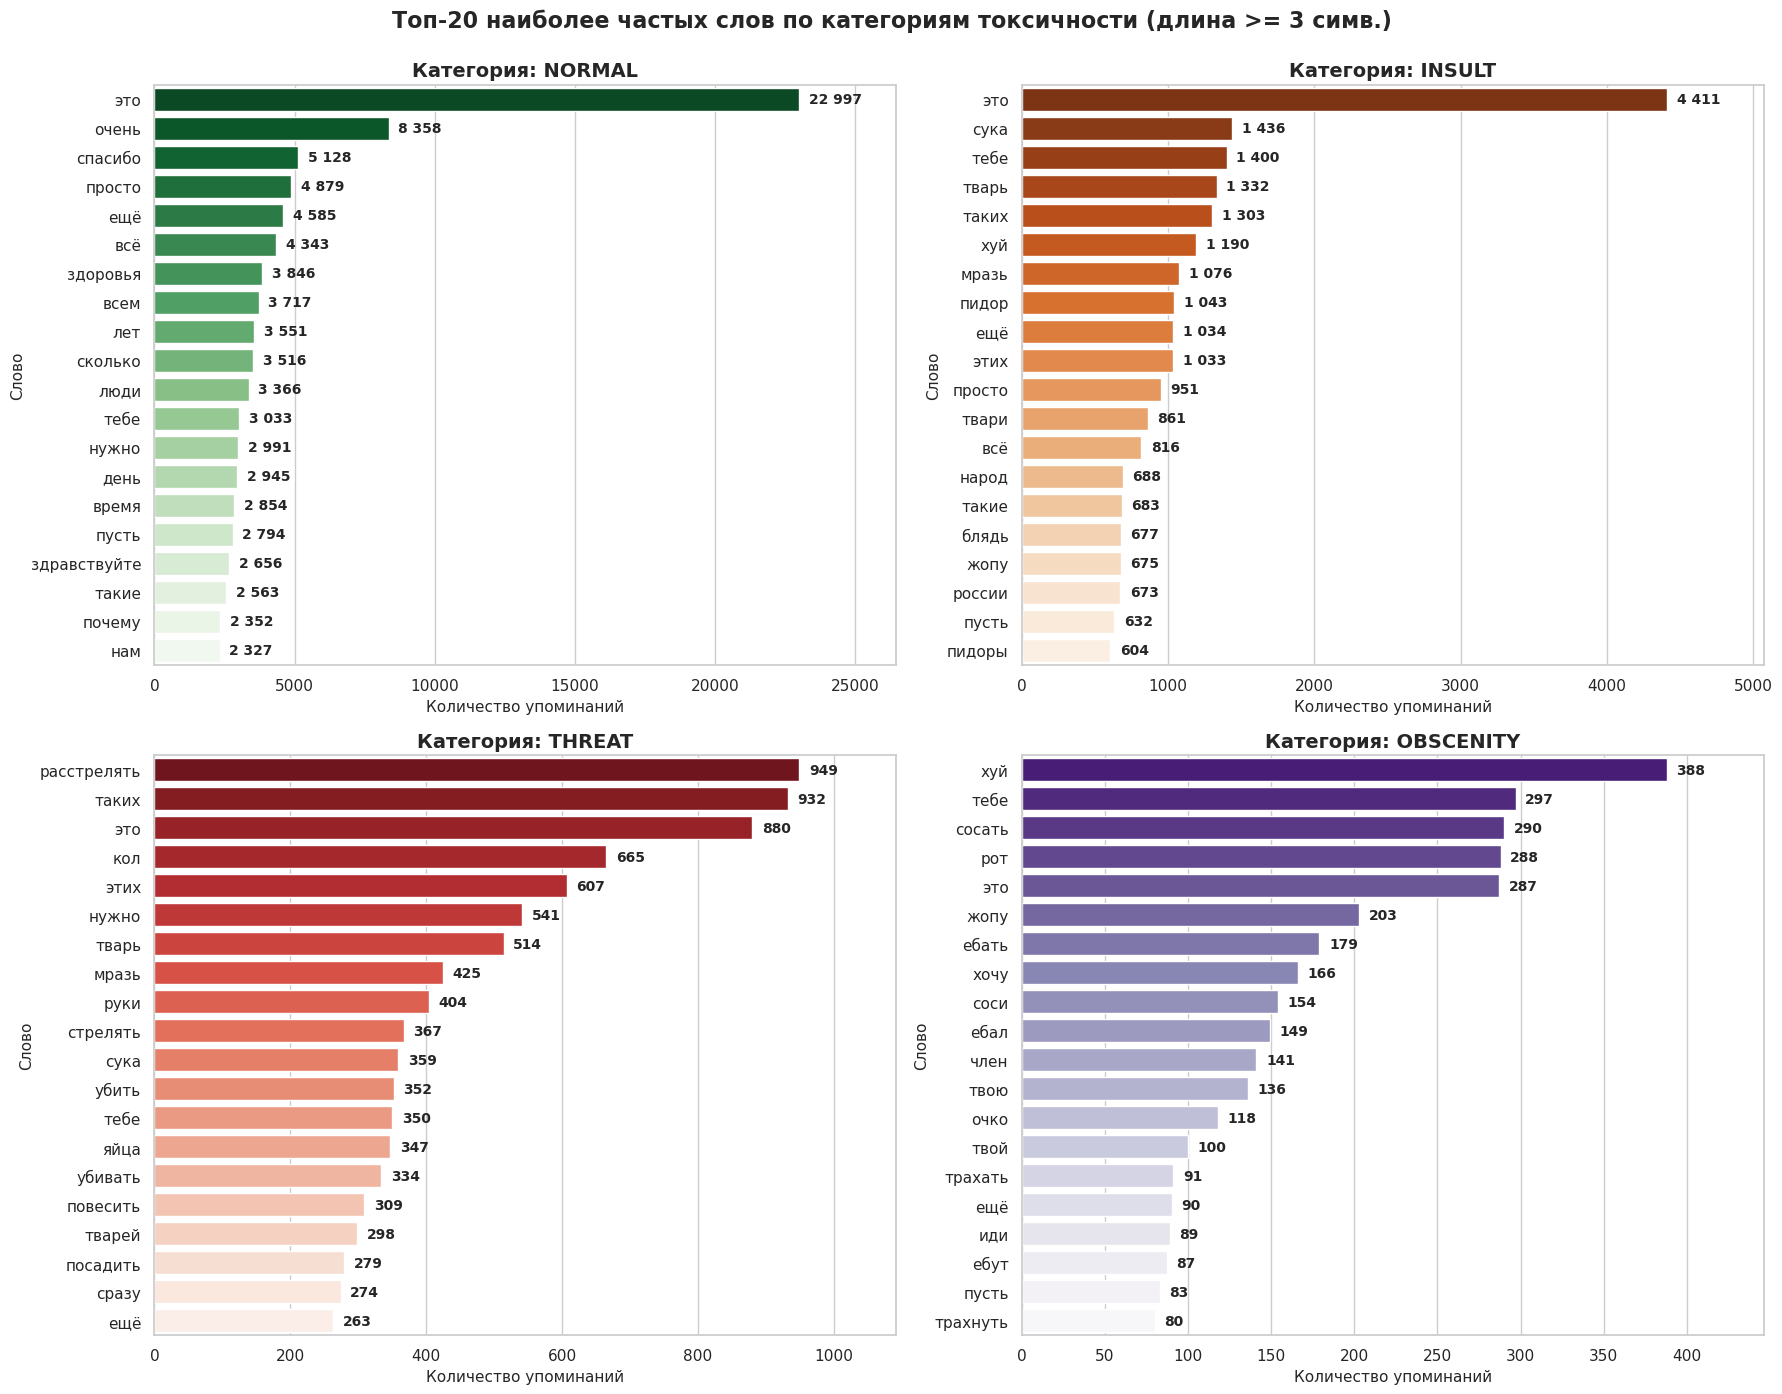

In [10]:
# Визуализация наиболее часто встречающихся слов в датасете по меткам

# Создание сетки 2x2 и распаковка осей в отдельные переменные
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(18, 14))
axes_list = [ax1, ax2, ax3, ax4]
palettes = ['Greens_r', 'Oranges_r', 'Reds_r', 'Purples_r']

fig.suptitle(
    f'Топ-{n_words} наиболее частых слов по категориям токсичности (длина >= {n_gap} симв.)',
    fontsize=16,
    fontweight='bold',
    y=0.995
)

for idx, lab in enumerate(labels):
    top_words_list = count_words(df_updated, lab, stop_ru, n_words, n_gap)
       
    # Переменные для слов и их частот
    words, counts = zip(*top_words_list)
    ax = axes_list[idx]
    
    sns.barplot(
        x=list(counts),
        y=list(words),
        ax=ax,
        palette=palettes[idx],
        hue=list(words),
        legend=False
    )
    
    ax.set_title(f'Категория: {lab.upper()}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Количество упоминаний', fontsize=11)
    ax.set_ylabel('Слово', fontsize=11)
    ax.set_xlim(0, max(counts) * 1.15)
    
    # Добавление числовых подписей
    for i, count in enumerate(counts):
        ax.text(
            count + max(counts) * 0.015,
            i,
            f'{count:,}'.replace(',', ' '),
            va='center',
            fontsize=10,
            fontweight='bold'
        )

plt.tight_layout()
plt.show()


In [11]:
extra_stop_words = {'это', 'эта','этих','тебе','это', 'всё', 'ещё','еще','просто','такие','таких'}
stop_ru_upd = stop_ru | extra_stop_words #объединяем изначальное множество стоп-слов с выбранными стоп словами
n_words = 20 #число выдаваемых слов
n_gap = 3 # ограничение по длине выдаваемых слов
for lab in labels:
    print(f'Наиболее часто встречаемые слова для метки {lab}')
    top_words_list = count_words(df_updated, lab, stop_ru_upd,n_words, n_gap)
    for word, cnt in top_words_list:
        print(f"{word:20s} {cnt}")
    print("="*50)

Наиболее часто встречаемые слова для метки normal
очень                8358
спасибо              5128
здоровья             3846
всем                 3717
лет                  3551
сколько              3516
люди                 3366
нужно                2991
день                 2945
время                2854
пусть                2794
здравствуйте         2656
почему               2352
нам                  2327
людей                2257
бог                  2217
жизни                2152
фото                 2132
вообще               2055
жизнь                2009
Наиболее часто встречаемые слова для метки insult
сука                 1436
тварь                1332
хуй                  1190
мразь                1076
пидор                1043
твари                861
народ                688
блядь                677
жопу                 675
россии               673
пусть                632
пидоры               604
нужно                567
люди                 553
нахуй                546


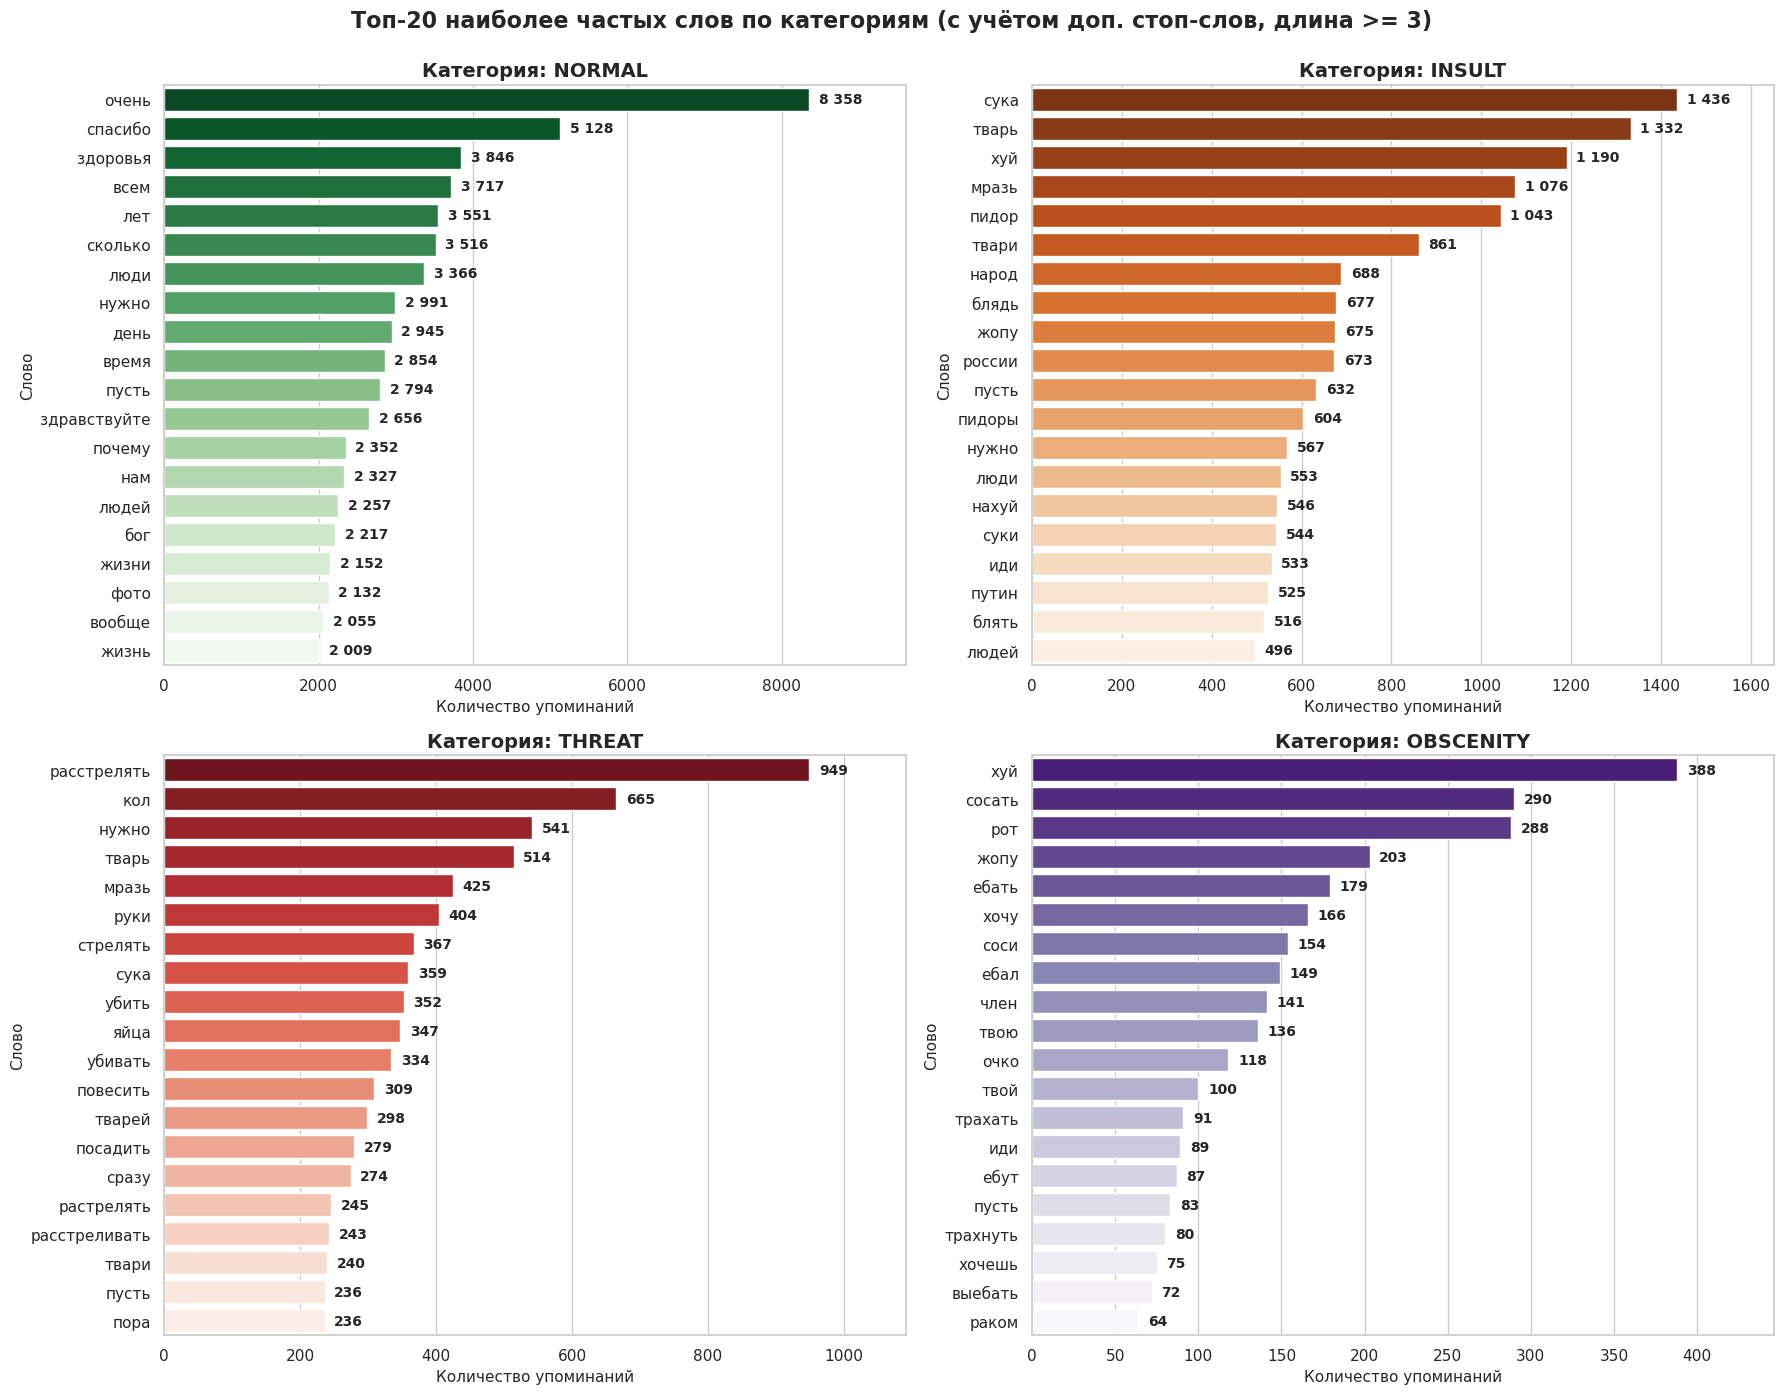

In [12]:
# Визуализация часто встречаемых слов с учётом дополнительного списка стоп-слов
# extra_stop_words = {'это', 'эта', 'этих', 'тебе', 'всё', 'ещё', 'еще', 'просто', 'такие', 'таких'}
# stop_ru_upd = stop_ru | extra_stop_words  # объединение словарей стоп-слов

# Создание сетки 2x2 и распаковка осей в отдельные переменные
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(18, 14))
axes_list = [ax1, ax2, ax3, ax4]
palettes = ['Greens_r', 'Oranges_r', 'Reds_r', 'Purples_r']

fig.suptitle(
    f'Топ-{n_words} наиболее частых слов по категориям (с учётом доп. стоп-слов, длина >= {n_gap})',
    fontsize=16,
    fontweight='bold',
    y=0.995
)

for idx, lab in enumerate(labels):
    top_words_list = count_words(df_updated, lab, stop_ru_upd, n_words, n_gap)
       
    # Переменные для слов и их частот
    words, counts = zip(*top_words_list)
    ax = axes_list[idx]
    
    sns.barplot(
        x=list(counts),
        y=list(words),
        ax=ax,
        palette=palettes[idx],
        hue=list(words),
        legend=False
    )
    
    ax.set_title(f'Категория: {lab.upper()}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Количество упоминаний', fontsize=11)
    ax.set_ylabel('Слово', fontsize=11)
    ax.set_xlim(0, max(counts) * 1.15)
    
    # Добавление числовых подписей
    for i, count in enumerate(counts):
        ax.text(
            count + max(counts) * 0.015,
            i,
            f'{count:,}'.replace(',', ' '),
            va='center',
            fontsize=10,
            fontweight='bold'
        )

plt.tight_layout()
plt.show()


_______________________________________________
Выводы по шагу 6:
2. Наиболее часто встречающиеся слова в датасете представляют собой нейтральные слова. Это может быть связано с тем, что больше 80% сообщений в датасете представляют собой нейтральные сообщения. Также можно отметить, что неучет слов с небольшим количеством знаков приводит к большему пониманию смысла выдаваемых слов: убираются мусорные слова, знаки препинания, случайные буквы и т.д.;
3. Несмотря на улучшение контекста выдаваемых слов при условии количества букв не менее 4 (к примеру), это приводит к сокращению в выдаче матерных слов "хуй" (к примеру), так что это граница видится крайне субъективной. В дальнейшем, при обучении модели, могут понадобиться именно слова с определенным смыслов из данных категорий, поэтому это видится крайне важным вопросом. Возможно, стоит добавить в список стоп-слов такие слова как "это", которые не выражают определенного, однозначного смысла.
4. Видно, что метка normal содержит нейтральные слова. Метка insult - слова-оскорбления (за исключением нейтральных слов, которые можно также обозначить как стоп-слова в будущем), метка threat - слова, связанные с угрозой или намерением (стрелять, расстрелять), также здесь присутсвуют оскорбительные слова (замешанные с нейтральными, потенциальными стоп-словами), метка obscenity - слова с матерной лексикой (в данном случае нейтральных слов меньше, чем для остальных меток). Можно сделать вывод о том, что анализируемый датасет представляет собой удобные для обучения данные, где слова семантически разделены по соответсвующим группам
5. Добавление новых стоп-слов, найденных по результатам анализа топ-слов для каждой метки, помогает конкретизировать облако топ-слов, характерных для рассматриваемых категорий в датасете, как видно из полученных результатов.
6. В метке insult встречаются такие слова как "путин, народ, россии" - политически-окрашенные слова. Возможно, в будущем, при обучении, могут возникнуть проблемы именно вследствие того, что политически-нейтральные тексты также будут считываться как insult, если в них будут встречаться подобные слова. На это стоит обратить внимание.
_______________________________________________

_______________________________________________
Основные выводы по EDA анализу:
1. Всего в датасете представлено изначально 248290 объекта и 5 признаков. В датасете отсутствовали пропуски, обнаруженные дубликаты были обработаны и удалены. Обновленный датасет в ноутбуке - df_updated;
2. Можно отметить достаточно сильный дисбаланс классов в сторону normal. Потенциально это говорит о том, что в будущем нужно аккуратно выбирать метрики под модели - стандартные метрики вроде Accuracy тут работать не будут
Процентное соотношение сообщений каждой из категорий относительно всего корпуса:
    normal       82.03 %
    insult       14.83 %
    threat        4.84 %
    obscenity     1.72 %
4. В сообщениях присутствуют фрагменты длиной от 1 до 267 слов, при этом максимальное число символов составляет 998 штук, медианы len_words: normal ~7, insult ~9, threat ~8, obscenity ~8 - то есть длина сообщения и количество символов представляются незначительными для дополнительного анализа признаками, они ничего не показывают
5. Наиболее часто встречающиеся слова в датасете представляют собой нейтральные слова. Это может быть связано с тем, что больше 80% сообщений в датасете представляют собой нейтральные сообщения. Также можно отметить, что неучет слов с небольшим количеством знаков приводит к больше пониманию смысла выдаваемых слов: убираются мусорные слова, знаки препинания, случайные буквы и т.д.;
6. Несмотря на улучшение контекста выдаваемых слов при условии количества букв не менее 4 (к примеру), это приводит к сокращению в выдаче матерных слов "хуй" (к примеру), так что это граница видится крайне субъективной. В дальнейшем, при обучении модели, могут понадобиться именно слова с определенным смыслов из данных категорий, поэтому это видится крайне важным вопросом. Возможно, стоит добавить в список стоп-слов такие слова как "это", которые не выражают определенного, однозначного смысла.
7. Видно, что метка normal содержит нейтральные слова. Метка insult - слова-оскорбления (за исключением нейтральных слов, которые можно также обозначить как стоп-слова в будущем), метка threat - слова, связанные с угрозой или намерением (стрелять, расстрелять), также здесь присутсвуют оскорбительные слова (замешанные с нейтральными, потенциальными стоп-словами), метка obscenity - слова с матерной лексикой (в данном случае нейтральных слов меньше, чем для остальных меток). Можно сделать вывод о том, что анализируемый датасет представляет собой удобные для обучения данные, где слова семантически разделены по соответсвующим группам, но это не отменяет дисбаланса классов - их надо учитывать при моделировании».
8. В метке insult встречаются такие слова как "путин, народ, россии" - политически-окрашенные слова. Возможно, в будущем, при обучении, могут возникнуть проблемы именно вследствие того, что политически-нейтральные тексты также будут считываться как insult, если в них будут встречаться подобные слова. На это стоит обратить внимание.
9. В сообщениях большое количество эмодзи, которые релевантны для разметки, а также присутствует латиница (транслит, замена букв для обхода блокировок). Нужно учитывать это при дальнейшей работе с данными.
10. Видится полезным использование списка стоп-слов и его расширение (например, добавление форм личных и притяжательных местоимений) для корректной разметки.
11. Вероятно, имеет смысл добавить как признаки меток сочетания слов, которые именно вместе не являются нейтральными, а говорят об угрозе или оскорблении.
_______________________________________________